# 02. 가중치를 평균하기 — LAWA와 schedule-free

학습률을 일정하게 두면 가중치는 손실이 낮은 곳 근처에서 gradient noise 때문에 계속 흔들립니다. 보통은 cosine처럼 학습률을 0까지 줄여 흔들림을 잠재웁니다. 하지만 그러려면 학습 길이를 미리 정해야 하고, 학습을 나눠(chunk) 이어 가기도 번거롭습니다. 흔들리는 가중치 여러 개를 **평균**하면 학습률을 줄이지 않고도 흔들림을 지울 수 있습니다. 이 저장소에는 두 가지가 학습 옵션으로 들어 있습니다(issue #46, nanoTabPFN speedrun).

- **LAWA**(latest weight averaging): 일정 step마다 남긴 가중치 최근 K개를 평균해 검증·저장합니다. 학습 자체는 바꾸지 않습니다. `TrainConfig(weight_average=K, weight_average_every=...)`
- **schedule-free AdamW**(Defazio et al. 2024): 평균을 optimizer 안에서 들고 가며, 학습률은 warmup 뒤 일정하게 둡니다. `TrainConfig(schedule_free=True)`, `minipfn/training/schedule_free.py`

다루는 흐름:

1. 1차원에서 보기 — 흔들리는 점과 그 평균
2. schedule-free의 세 점 — z, x, y
3. 작은 모델로 견주기
4. 정리

## `minipfn` 불러오기

다른 노트북과 같은 import shim입니다. 이 노트북은 `notebooks/topics_training/` 아래에 있으므로 저장소 루트는 두 단계 위입니다. 3절은 [01 Muon](01_muon.ipynb)과 같은 작은 모델과 prior를 쓰고 CPU에서 2분쯤 걸립니다.

In [1]:
try:
    import minipfn
except ImportError:
    import sys
    from pathlib import Path

    sys.path.insert(0, str(Path.cwd().parents[1] / "src"))
    import minipfn

In [2]:
import collections
import copy
import math
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

from minipfn import set_seed
from minipfn.training.config import TrainConfig
from minipfn.training.loop import _average_states  # LAWA 평균 (학습 루프 내부 함수)
from minipfn.training.losses import prior_loss
from minipfn.training.schedule_free import ScheduleFreeAdamW

set_seed(0)  # 재현성을 위해 난수 시드를 고정한다.

## 1. 1차원에서 보기 — 흔들리는 점과 그 평균

가중치가 숫자 하나 $w$이고 손실이 $(w - 3)^2$인 그릇 모양이라고 합시다. 가장 낮은 곳은 $w = 3$입니다. gradient $2(w - 3)$에 매 step 표준편차 4짜리 noise가 섞여 들어옵니다. 실제 학습에서 batch마다 gradient가 다른 것과 같습니다. 0에서 출발해 SGD로 200 step을 갑니다.

- **일정한 학습률 0.1**: 3 근처까지 빨리 가지만 거기서 계속 흔들립니다.
- **cosine 학습률**(0.1에서 0으로): 끝으로 갈수록 덜 움직여 흔들림이 줄어듭니다.
- **일정한 학습률 + LAWA**: 일정한 학습률 그대로 가면서 10 step마다 $w$를 남기고, 최근 5개(50 step 치)를 평균합니다.

In [3]:
rng = np.random.default_rng(0)
STEPS_1D = 200
noise = rng.normal(0.0, 4.0, STEPS_1D)  # 세 방법이 같은 noise를 받는다


def sgd_path(lr_at):
    w, path = 0.0, []
    for step in range(STEPS_1D):
        gradient = 2 * (w - 3.0) + noise[step]
        w -= lr_at(step) * gradient
        path.append(w)
    return np.array(path)


constant = sgd_path(lambda s: 0.1)
cosine = sgd_path(lambda s: 0.1 * 0.5 * (1 + math.cos(math.pi * s / STEPS_1D)))

# LAWA: 10 step마다 남긴 w의 최근 5개 평균 (남긴 것이 5개가 된 뒤부터)
snapshots = collections.deque(maxlen=5)
lawa = np.full(STEPS_1D, np.nan)
for step, w in enumerate(constant):
    if (step + 1) % 10 == 0:
        snapshots.append(w)
    if len(snapshots) == 5:
        lawa[step] = np.mean(snapshots)

last = slice(150, 200)  # 마지막 50 step
one_d = pd.DataFrame(
    {
        "마지막 w": [constant[-1], cosine[-1], lawa[-1]],
        "마지막 50 step의 |w − 3| 평균": [
            np.abs(constant[last] - 3).mean(),
            np.abs(cosine[last] - 3).mean(),
            np.abs(lawa[last] - 3).mean(),
        ],
    },
    index=["일정한 lr", "cosine lr", "일정한 lr + LAWA (5개)"],
)
display(one_d.round(3))

,마지막 w,마지막 50 step의 |w − 3| 평균
일정한 lr,3.192,0.536
cosine lr,3.098,0.104
일정한 lr + LAWA (5개),3.345,0.233


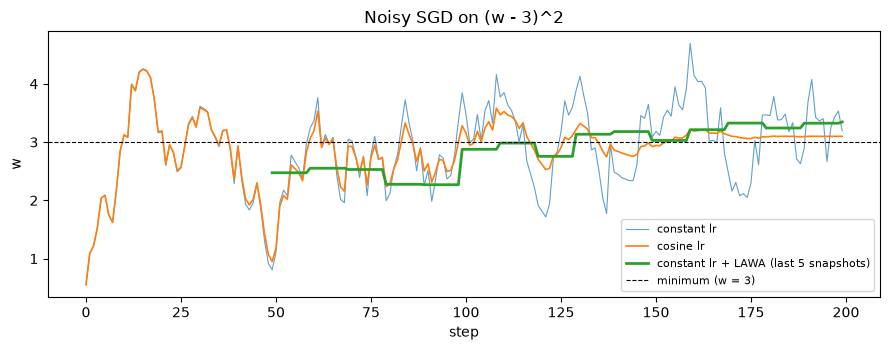

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(constant, lw=0.8, alpha=0.7, label="constant lr")
ax.plot(cosine, lw=1.2, label="cosine lr")
ax.plot(lawa, lw=2, label="constant lr + LAWA (last 5 snapshots)")
ax.axhline(3.0, color="k", lw=0.8, ls="--", label="minimum (w = 3)")
ax.set_xlabel("step")
ax.set_ylabel("w")
ax.set_title("Noisy SGD on (w - 3)^2")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

일정한 학습률은 마지막 50 step 동안 3에서 평균 0.54씩 떨어진 채 흔들립니다. cosine은 끝으로 갈수록 학습률이 0에 가까워져 0.10으로 가장 가깝습니다. LAWA는 학습률을 줄이지 않고도 0.23까지 줄입니다. 흔들리는 점 다섯 개를 평균하면 흔들림이 서로 지워지기 때문입니다. 대신 50 step 치를 평균하므로 한 박자 늦게 따라갑니다.

## 2. schedule-free의 세 점 — z, x, y

schedule-free AdamW는 파라미터마다 점 세 개를 들고 갑니다.

- **z**: SGD처럼 gradient 방향으로 가는 점입니다(일정한 학습률이라 흔들립니다).
- **x**: 지금까지 지나온 z의 평균입니다. 검증하고 저장하는 가중치가 이것입니다.
- **y** = $(1 - \beta_1)\, z + \beta_1\, x$: gradient를 계산하는 점입니다. 학습 중 모델 파라미터에는 y가 들어 있습니다($\beta_1 = 0.9$).

LAWA가 "최근 몇 개"의 평균이라면, x는 처음부터의 가중 평균입니다(step $k$의 가중치는 그때 학습률의 제곱). 1절의 문제를 `ScheduleFreeAdamW`로 풀며 세 점을 기록합니다. 학습률은 1절과 같은 0.1입니다. 저장소 학습 루프처럼 처음 20 step만 warmup하고 그 뒤로는 일정하게 둡니다.

In [5]:
w = torch.nn.Parameter(torch.zeros(1))
optimizer = ScheduleFreeAdamW([w], lr=0.1)
warmup = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda s: min(1.0, (s + 1) / 20))
points = {"y (gradient를 계산하는 점)": [], "z": [], "x (평균, 검증·저장)": []}
for step in range(STEPS_1D):
    loss = (w - 3.0) ** 2 + w * noise[step]  # gradient = 2(w − 3) + noise
    optimizer.zero_grad()
    loss.sum().backward()
    optimizer.step()
    warmup.step()
    points["y (gradient를 계산하는 점)"].append(w.item())
    points["z"].append(optimizer.state[w]["z"].item())
    points["x (평균, 검증·저장)"].append(optimizer.average(w).item())
points = pd.DataFrame(points)
display(points.iloc[[9, 49, 99, 199]].rename(index=lambda i: f"{i + 1} step").round(3))
print("마지막 50 step의 |값 − 3| 평균:", (points.iloc[150:] - 3).abs().mean().round(3).to_dict())

,y (gradient를 계산하는 점),z,"x (평균, 검증·저장)"
10 step,0.176,0.279,0.164
50 step,1.611,1.954,1.573
100 step,2.459,3.601,2.332
200 step,3.321,4.079,3.236


마지막 50 step의 |값 − 3| 평균: {'y (gradient를 계산하는 점)': 0.2, 'z': 1.147, 'x (평균, 검증·저장)': 0.116}


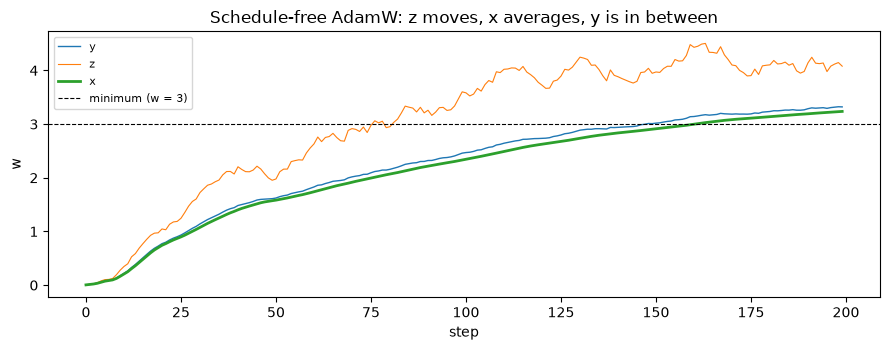

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.6))
for name, lw in zip(points.columns, [1.0, 0.8, 2.0], strict=True):
    ax.plot(points[name].to_numpy(), lw=lw, label=name.split(" ")[0])
ax.axhline(3.0, color="k", lw=0.8, ls="--", label="minimum (w = 3)")
ax.set_xlabel("step")
ax.set_ylabel("w")
ax.set_title("Schedule-free AdamW: z moves, x averages, y is in between")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

z는 4 근처까지 올라가 흔들립니다(마지막 50 step 동안 3에서 평균 1.15). gradient를 z가 아니라 y에서 재기 때문입니다. y가 아직 3보다 낮은 동안에는 gradient가 계속 "올라가라"고 하므로 z는 3을 지나쳐 올라갑니다. x는 지나온 z의 평균이라 매끄럽고, 마지막 50 step 동안 3에서 평균 0.12만 떨어져 있어 1절의 cosine(0.10)에 가깝습니다. 학습률을 한 번도 줄이지 않았는데도 그렇습니다. 대신 x는 처음부터의 평균이라 천천히 올라갑니다(50 step에서 1.57, 100 step에서 2.33).

## 3. 작은 모델로 견주기

[01 Muon](01_muon.ipynb) 4절과 같은 작은 모델(v2 구조, 폭 64, 층 3개)과 graph SCM prior batch로 300 step을 학습합니다. 세 가지를 견줍니다. 모두 Adam 계열이고 기준 학습률은 3e-3, warmup은 30 step입니다.

- **cosine**: warmup 뒤 cosine으로 0까지(저장소 기본).
- **constant + LAWA**: warmup 뒤 일정한 학습률. 25 step마다 가중치를 남기고 최근 4개(100 step 치)의 평균으로 검증합니다.
- **schedule-free**: warmup 뒤 일정한 학습률. 평균 x로 검증합니다.

50 step마다 검증 batch 6개의 손실을 잽니다. LAWA는 남긴 가중치가 4개가 된 100 step부터 잽니다.

In [7]:
config = TrainConfig(
    task="classification",
    emsize=64,
    nlayers=3,
    nhead=4,
    max_train_rows=128,
    n_eval_rows=64,
    max_features=8,
    micro_batch=16,
    val_batch=16,
)
start = time.perf_counter()
train_prior = config.make_prior(0)
train_batches = [train_prior.sample_batch(config.micro_batch) for _ in range(60)]
val_prior = config.make_prior(10_000_000)
val_batches = [val_prior.sample_batch(config.val_batch) for _ in range(6)]
print(f"prior에서 batch 66개: {time.perf_counter() - start:.0f}초")

STEPS, WARMUP, EVAL_EVERY, LR = 300, 30, 50, 3e-3
LAWA_K, LAWA_EVERY = 4, 25


def batch_loss(model, batch):
    logits = model(batch.x, batch.y[:, : batch.n_train])
    return prior_loss(logits, batch.y[:, batch.n_train :], "classification", None)


def validation_loss(model):
    model.eval()
    with torch.no_grad():
        loss = np.mean([batch_loss(model, b).item() for b in val_batches])
    model.train()
    return loss


def model_with(state, template):
    evaluated = copy.deepcopy(template)
    evaluated.load_state_dict(state)
    return evaluated

prior에서 batch 66개: 26초


In [8]:
def train(method):
    torch.manual_seed(0)  # 모델 초기값을 같게
    model = config.build_model()
    warmup = lambda s: min(1.0, (s + 1) / WARMUP)  # noqa: E731
    if method == "schedule-free":
        optimizer = ScheduleFreeAdamW(model.parameters(), lr=LR)
        factor = warmup  # 저장소 루프처럼 warmup만
    else:
        optimizer = torch.optim.Adam(model.parameters(), lr=LR)
        if method == "cosine":
            factor = lambda s: warmup(s) * 0.5 * (1 + math.cos(math.pi * s / STEPS))  # noqa: E731
        else:
            factor = warmup
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, factor)
    snapshots = collections.deque(maxlen=LAWA_K)
    curve = []
    for step in range(STEPS):
        loss = batch_loss(model, train_batches[step % len(train_batches)])
        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()
        done = step + 1
        if method == "constant + LAWA" and done % LAWA_EVERY == 0:
            snapshots.append({k: v.detach().clone() for k, v in model.state_dict().items()})
        if done % EVAL_EVERY:
            continue
        if method == "schedule-free":
            # 검증할 가중치는 평균 x (학습 파라미터에는 y가 들어 있다)
            state = {n: optimizer.average(p) for n, p in model.named_parameters()}
            evaluated = model_with({**model.state_dict(), **state}, model)
        elif method == "constant + LAWA":
            if len(snapshots) < LAWA_K:
                continue
            evaluated = model_with(_average_states(list(snapshots)), model)
        else:
            evaluated = model
        row = {"step": done, "검증 손실": validation_loss(evaluated)}
        if method == "constant + LAWA":
            row["평균 안 한 가중치"] = validation_loss(model)
        curve.append(row)
    return pd.DataFrame(curve).set_index("step")


curves = {}
for method in ["cosine", "constant + LAWA", "schedule-free"]:
    start = time.perf_counter()
    curves[method] = train(method)
    print(f"{method}: {time.perf_counter() - start:.0f}초")
table = pd.concat({m: c["검증 손실"] for m, c in curves.items()}, axis=1)
table["constant (평균 안 함)"] = curves["constant + LAWA"]["평균 안 한 가중치"]
display(table.round(4))

cosine: 14초


constant + LAWA: 16초


schedule-free: 17초


,cosine,constant + LAWA,schedule-free,constant (평균 안 함)
step,,,,
50,1.7546,NaN,1.7039,NaN
100,1.7048,1.6704,1.5573,1.6720
150,1.5385,1.5946,1.5087,1.5973
200,1.5211,1.5452,1.4705,1.5454
250,1.4948,1.5167,1.4363,1.5503
300,1.4870,1.5206,1.4056,1.6493


300 step에서 schedule-free가 가장 낮고(1.406), cosine(1.487), constant + LAWA(1.521) 순서입니다. 평균하지 않은 일정한 학습률의 가중치는 250 step 뒤 오히려 나빠져 1.649까지 올라갑니다. 같은 학습에서 최근 4개를 평균한 LAWA는 1.521이라, 그 흔들림을 대부분 지웠습니다.

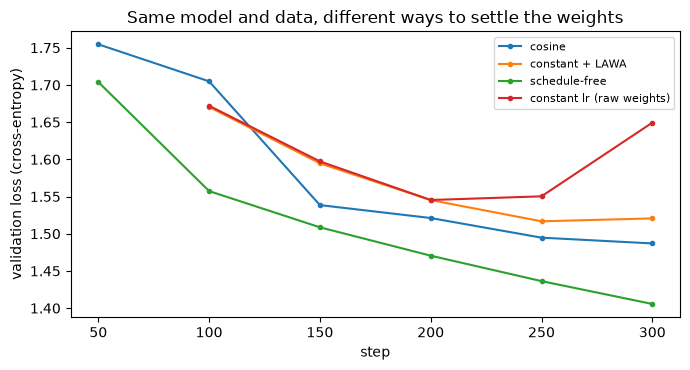

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.8))
labels = {"constant (평균 안 함)": "constant lr (raw weights)"}
for column in table.columns:
    series = table[column].dropna()
    ax.plot(series.index, series.to_numpy(), marker="o", ms=3, label=labels.get(column, column))
ax.set_xlabel("step")
ax.set_ylabel("validation loss (cross-entropy)")
ax.set_title("Same model and data, different ways to settle the weights")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

빨간 선(일정한 학습률의 가중치 그대로)은 끝에서 튀고, 주황 선(같은 학습의 LAWA)은 그 튐을 따라가지 않습니다. 학습은 같고 검증하는 가중치만 다릅니다. schedule-free는 처음부터 끝까지 가장 낮습니다. 다만 이것은 300 step짜리 toy의 결과이고, 이 저장소의 v3.5 medium 비교에서는 schedule-free가 cosine보다 낫지 않았습니다(4절). 학습 길이에 따라 결과가 달라질 수 있습니다.

## 4. 정리

| | 흔들림을 줄이는 방법 | 학습 길이를 미리 알아야 하나 | 학습 설정 |
|---|---|---|---|
| cosine | 학습률을 0까지 줄인다 | 예 | 기본 |
| LAWA | 최근 K개 가중치를 평균해 검증·저장한다(학습은 그대로) | 아니오 | `weight_average=K`, `weight_average_every` |
| schedule-free | optimizer가 평균 x를 들고 가고, gradient는 y에서 잰다 | 아니오 | `schedule_free=True` |

- 평균은 학습률을 줄이지 않고도 흔들림을 지웁니다(1·2절).
- LAWA는 학습을 전혀 바꾸지 않으므로 cosine 학습에도 켤 수 있습니다. 저장소는 마지막에 평균 가중치를 `final_avg.pt`로 따로 남깁니다.
- 이 저장소의 v3.5 medium 비교(PR #50)에서는 LAWA가 평균 손실을 조금 낮췄고, schedule-free는 이득이 없었습니다.